# Defense-start-round results — seed mean/min/max

Companion to `plotting.ipynb` (left untouched, kept as reference for the old
raw-single-run figures). This notebook re-derives the same "defense doesn't
start until round X" figures, but:

- pulls fresh data straight from the wandb API instead of the (partially
  hand-patched, now stale) `all_start_rounds*.csv` files,
- averages over every seed actually available (0 = the original run, no
  `seed` key logged; 43, 44 = the current sweeps) instead of showing one
  run's raw numbers,
- plots the mean with the min/max across seeds shown as error bars (bar
  charts) or a shaded band (round-vs-metric line plots), instead of a single
  point estimate.

**Known data wrinkle (CIFAR-10, `defense_start_round` 50/100):** the original
(seed-0) sweeps for these two round values didn't consistently tie
`aggr_server` to `aggr` (some legacy sweep YAMLs swept them independently, or
left `aggr` at its `avg` default while only sweeping `aggr_server`). The
current seed-43/44 sweeps use `aggr_server: same`, which *does* correctly
apply the same defense on both servers — but wandb logs the sweep's literal
value `"same"` for `aggr_server` rather than the resolved defense name (a
wandb sweep-config quirk, not a training bug). This notebook treats
`aggr_server == "same"` as matching `aggr` by construction, and otherwise
only keeps runs where the *actually logged* `aggr` and `aggr_server` are
equal ("diagonal" runs = same defense applied on both servers). No manual
patching of any CSV — whatever the wandb API returns and passes this filter
is what gets plotted. Where a (dataset, attack, defense, defense_start_round)
combination only has 1 seed so far (sweeps are still running), that's shown
as-is with no error band rather than invented.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wandb

api = wandb.Api()

PROJECTS = [
    "adavarts-tuwien/sfl-with-start-round",  # legacy: original (seed-0, no `seed` key) runs
    "adavarts-tuwien/sfl2",                  # current: seed-43/44 sweeps, plus gtsrb's own seed-0 runs
]

ATTACKS = ["badnet", "DBA", "neurotoxin"]
DEFENSES_ORDER = ["mkrum", "alignins", "feddlad"]
DEFENSE_LABEL = {"mkrum": "MKrum", "foolsgold": "FoolsGold", "alignins": "AlignIns", "feddlad": "FedDLAD"}
ATTACK_LABEL = {"badnet": "BadNets", "DBA": "DBA", "neurotoxin": "Neurotoxin"}
COLOR_ASR = "#d62728"
COLOR_ACC = "#1f77b4"


## 1. Fetch raw runs

Pulls every run with `defense_start_round > 1` from both projects. A run's
`aggr_server` is resolved to `aggr` when it's literally the string `"same"`
(see note above); `is_diag` marks runs where the (resolved) `aggr_server`
equals `aggr` — i.e. the same defense was really applied on both servers.


In [2]:
def fetch_raw():
    records = []
    for project in PROJECTS:
        runs = api.runs(project, per_page=200)
        print(f"{project}: {len(runs)} runs total")
        for r in runs:
            cfg = r.config
            dsr = cfg.get("defense_start_round", 1)
            data = cfg.get("data")
            attack = cfg.get("attack")
            # a few broken sweep-launch runs log attack/data as the sweep's
            # list of *choices* instead of the resolved scalar -- they never
            # actually trained (state == failed, nothing logged)
            if isinstance(attack, list) or isinstance(data, list):
                continue
            if dsr is None or dsr == 1:
                continue
            summ = dict(r.summary)
            aggr = cfg.get("aggr", "avg")
            aggr_server_raw = cfg.get("aggr_server", "avg")
            effective_aggr_server = aggr if aggr_server_raw == "same" else aggr_server_raw
            records.append({
                "project": project,
                "run_id": r.id,
                "run_name": r.name,
                "state": r.state,
                "created_at": r.created_at,
                "data": data,
                "attack": attack,
                "attack_mode": cfg.get("attack_mode", "baseline"),
                "aggr": aggr,
                "aggr_server_raw": aggr_server_raw,
                "aggr_server": effective_aggr_server,
                "is_diag": aggr == effective_aggr_server,
                "defense_start_round": dsr,
                "rounds_cfg": cfg.get("rounds", 200),
                "target_class": cfg.get("target_class"),
                "multiple_servers": cfg.get("multiple_servers", False),
                "seed": cfg.get("seed", 0),
                "has_seed_key": "seed" in cfg,
                "final_round": summ.get("round"),
                "asr": summ.get("asr"),
                "clean_acc": summ.get("clean_acc"),
                "robustness": summ.get("robustness acc"),
            })
    return pd.DataFrame.from_records(records)


raw = fetch_raw()
print(f"\nTotal defense_start_round>1 records: {len(raw)}")
raw["data"].value_counts()


adavarts-tuwien/sfl-with-start-round: 159 runs total
adavarts-tuwien/sfl2: 762 runs total

Total defense_start_round>1 records: 298


cifar10    158
gtsrb       94
mnist       46
Name: data, dtype: int64

## 2. Seed-source trust + completeness

- CIFAR-10 / MNIST: a "seed 0" run is only trusted from the legacy
  `sfl-with-start-round` project (it predates the `seed` field entirely). Any
  `sfl2` run for these datasets should always carry an explicit seed
  (43/44); one that doesn't would be stray dev noise, not the original run.
- GTSRB: `sfl-with-start-round` has **zero** GTSRB runs at all, so GTSRB's
  seed-0 source is `sfl2`'s own no-`seed`-key sweeps
  (`attacks_GTSRB_{50,100,200}.yaml`) — legitimate for this dataset only.
- "Complete" = state `finished` and it actually reached its configured round
  count (`rounds_cfg`, which varies: some `defense_start_round=200/300`
  sweeps extended total training to 400/500 rounds).


In [3]:
def seed_is_trusted(row):
    if row["data"] == "gtsrb":
        return True
    if row["has_seed_key"]:
        return True
    return row["project"] == "adavarts-tuwien/sfl-with-start-round"


raw["seed_trusted"] = raw.apply(seed_is_trusted, axis=1)
untrusted = raw[~raw["seed_trusted"]]
if len(untrusted):
    print(f"Dropping {len(untrusted)} untrusted-seed0 rows (dev noise, not the original run):")
    display(untrusted[["data", "attack", "defense_start_round", "aggr", "aggr_server_raw", "run_id"]])

raw = raw[raw["seed_trusted"]].copy()
raw["complete"] = (raw["state"] == "finished") & (raw["final_round"] >= raw["rounds_cfg"])

incomplete = raw[~raw["complete"]]
print(f"\n{len(incomplete)} incomplete/excluded rows (still running, crashed, or short) -- these will simply be "
      f"missing from the plots below, not estimated:")
incomplete[["data", "attack", "defense_start_round", "aggr", "aggr_server", "state", "final_round", "rounds_cfg", "run_id"]]



5 incomplete/excluded rows (still running, crashed, or short) -- these will simply be missing from the plots below, not estimated:


,data,attack,defense_start_round,aggr,aggr_server,state,final_round,rounds_cfg,run_id
77,cifar10,neurotoxin,300,mkrum,feddlad,crashed,108,500,yk0c7qnf
78,mnist,badnet,50,feddlad,alignins,crashed,158,200,8i27x9un
159,gtsrb,DBA,100,foolsgold,foolsgold,running,26,200,qsfixyd0
235,gtsrb,neurotoxin,50,feddlad,feddlad,crashed,8,200,set9v8qo
237,gtsrb,badnet,50,alignins,alignins,crashed,12,200,ltdzddst


`multiple_servers` is documented in `sfl.py`'s `sfl_variant` docstring as a
memory-optimization-only flag ("same math") for the default v1 variant, and
GTSRB's original seed-0 runs happen to have used `multiple_servers=True`
while the seed-43/44 sweeps use `False` -- exactly the same discrepancy
already investigated and approved for merging in the main results table
pipeline (`extract_seed_results.py`'s Decision 3: GTSRB's own seed-to-seed
noise is 10-32pp, dwarfing whatever gap this flag could cause). So it's left
out of `GROUP_COLS` below -- seeds merge across it for every dataset, which
only actually *does* anything for GTSRB (checked explicitly below). If
`target_class` ever turned out to differ within a group that would be a real
problem (a different backdoor target, not a memory optimization) -- checked
separately, and doesn't happen for this data (uniformly 7 for cifar10/mnist,
12 for gtsrb).


**Manual seed-0 substitution (cifar10/DBA/`dsr=50`, FedDLAD and AlignIns
both-servers cells)**: no true diagonal (`aggr==aggr_server`) seed-0 run
exists for either cell -- the legacy `DBA_CF_round.yaml` sweep only ever
paired FedDLAD/AlignIns with `aggr=avg` (an MS-only defense run), never with
`aggr` set to the same defense too. (MKrum needs no override -- it already
has a real diagonal seed-0 run, `vhkcwn86`.) User-approved best-effort
substitute (2026-08-13): treat those two MS-only runs (`1an2tir6` for
FedDLAD, `o7c4t8zp` for AlignIns) as the seed-0 stand-in for their cells
anyway, same spirit as the `recency_fallback`/`reference_exists_no_match`
promotions in `extract_seed_results.py` for GTSRB cells with no exact
seed-0 match.


In [4]:
OVERRIDE_AS_DIAG = {"1an2tir6": "feddlad", "o7c4t8zp": "alignins"}  # run_id -> the aggr value to treat it as
for run_id, forced_aggr in OVERRIDE_AS_DIAG.items():
    mask = raw["run_id"] == run_id
    raw.loc[mask, "aggr"] = forced_aggr
    raw.loc[mask, "is_diag"] = True

df = raw[raw["complete"]].copy()
diag = df[df["is_diag"]].copy()
print(f"{len(diag)} complete DIAGONAL (same defense on both servers) rows out of {len(df)} complete rows total")

GROUP_COLS = ["data", "attack", "attack_mode", "aggr", "defense_start_round", "rounds_cfg"]

for key, g in diag.groupby(GROUP_COLS):
    if g["target_class"].nunique() > 1:
        print(f"REAL PROBLEM: heterogeneous target_class within group {key} -- would silently mix two different backdoor targets")
    if g["multiple_servers"].nunique() > 1:
        tag = "expected (GTSRB seed0-vs-43/44 merge, see above)" if key[0] == "gtsrb" else "UNEXPECTED for this dataset"
        print(f"multiple_servers differs within group {key} -- {tag}")


208 complete DIAGONAL (same defense on both servers) rows out of 293 complete rows total
multiple_servers differs within group ('gtsrb', 'DBA', 'baseline', 'alignins', 50, 200) -- expected (GTSRB seed0-vs-43/44 merge, see above)
multiple_servers differs within group ('gtsrb', 'DBA', 'baseline', 'alignins', 100, 200) -- expected (GTSRB seed0-vs-43/44 merge, see above)
multiple_servers differs within group ('gtsrb', 'DBA', 'baseline', 'alignins', 200, 500) -- expected (GTSRB seed0-vs-43/44 merge, see above)
multiple_servers differs within group ('gtsrb', 'DBA', 'baseline', 'feddlad', 50, 200) -- expected (GTSRB seed0-vs-43/44 merge, see above)
multiple_servers differs within group ('gtsrb', 'DBA', 'baseline', 'feddlad', 100, 200) -- expected (GTSRB seed0-vs-43/44 merge, see above)
multiple_servers differs within group ('gtsrb', 'DBA', 'baseline', 'foolsgold', 50, 200) -- expected (GTSRB seed0-vs-43/44 merge, see above)
multiple_servers differs within group ('gtsrb', 'DBA', 'baseline', 'm

## 3. Aggregate across seeds (mean, min, max)

In [5]:
def aggregate(sub):
    rows = []
    for key, g in sub.groupby(GROUP_COLS):
        # de-dup: if the same (config, seed) somehow has 2+ complete runs,
        # keep the most-recently-created one
        g = g.sort_values("created_at").groupby("seed", as_index=False).tail(1)
        row = dict(zip(GROUP_COLS, key))
        for metric in ("asr", "clean_acc", "robustness"):
            vals = g[metric].dropna().astype(float).tolist()
            if vals:
                row[f"{metric}_mean"] = float(np.mean(vals))
                row[f"{metric}_min"] = float(np.min(vals))
                row[f"{metric}_max"] = float(np.max(vals))
            else:
                row[f"{metric}_mean"] = row[f"{metric}_min"] = row[f"{metric}_max"] = None
        row["n_seeds"] = g["seed"].nunique()
        row["seeds"] = sorted(g["seed"].unique().tolist())
        rows.append(row)
    return pd.DataFrame(rows)


agg = aggregate(diag)
agg.to_csv("seed_avg_start_round.csv", index=False)
print(f"{len(agg)} aggregated groups -> seed_avg_start_round.csv")
agg.sort_values(["data", "defense_start_round", "attack", "aggr"])[
    ["data", "attack", "aggr", "defense_start_round", "rounds_cfg", "n_seeds", "seeds", "asr_mean", "asr_min", "asr_max"]
]


79 aggregated groups -> seed_avg_start_round.csv


,data,attack,aggr,defense_start_round,rounds_cfg,n_seeds,seeds,asr_mean,asr_min,asr_max
0,cifar10,DBA,alignins,50,200,3,"[0, 43, 44]",0.049222,0.039222,0.062111
3,cifar10,DBA,feddlad,50,200,3,"[0, 43, 44]",0.051593,0.039444,0.062667
6,cifar10,DBA,foolsgold,50,200,2,"[43, 44]",0.070278,0.052111,0.088444
8,cifar10,DBA,mkrum,50,200,3,"[0, 43, 44]",0.048481,0.035111,0.067889
11,cifar10,badnet,alignins,50,200,3,"[0, 43, 44]",0.055148,0.048444,0.065444
...,...,...,...,...,...,...,...,...,...,...
78,mnist,neurotoxin,mkrum,50,200,1,[0],0.999777,0.999777,0.999777
65,mnist,DBA,alignins,100,200,1,[0],1.000000,1.000000,1.000000
66,mnist,DBA,feddlad,100,200,1,[0],1.000000,1.000000,1.000000
67,mnist,DBA,foolsgold,100,200,1,[0],1.000000,1.000000,1.000000


## 4. Bar charts: ASR / Accuracy vs. defense, at a fixed `defense_start_round`

Bars show the mean; whiskers span [min, max] across whichever seeds are
available (`n=1` means only the original run exists so far -- no band to
show, not an error). CIFAR-10 and GTSRB are combined into one figure for
`defense_start_round` 50 and 100 (matching `plotting.ipynb`'s layout); for
`defense_start_round=200` they're kept as separate figures since that
experiment differs more between the two datasets (extended total rounds,
fewer defenses covered). MNIST gets its own figure(s) since it has no
seed-43/44 data at all yet -- bars there are single-run point estimates.


In [14]:
def plot_bar_panel(ax, sub_agg, attack, defense_start_round, show_xlabel=False):
    sub = sub_agg[(sub_agg["attack"] == attack) & (sub_agg["defense_start_round"] == defense_start_round)]
    # Some cells have 2 rows for the same aggr -- e.g. cifar10/badnet/dsr=200/
    # mkrum has a rounds_cfg=400 seed-0-only legacy row AND a rounds_cfg=500
    # seed-43/44 row (the original run was cut short at 400 rounds for that
    # one combo). Keep whichever variant has more seeds -- most informative
    # for display -- rather than crashing on the duplicate aggr label.
    sub = sub.sort_values("n_seeds", ascending=False).drop_duplicates(subset="aggr", keep="first")
    defenses = [d for d in DEFENSES_ORDER if d in sub["aggr"].values]
    if not defenses:
        ax.text(0.5, 0.5, "no data", ha="center", va="center", transform=ax.transAxes)
        return
    sub = sub.set_index("aggr").loc[defenses]

    asr_mean = (sub["asr_mean"] * 100).values
    asr_lo = np.clip(asr_mean - (sub["asr_min"] * 100).values, 0, None)
    asr_hi = np.clip((sub["asr_max"] * 100).values - asr_mean, 0, None)

    acc_mean = (sub["clean_acc_mean"] * 100).values
    acc_lo = np.clip(acc_mean - (sub["clean_acc_min"] * 100).values, 0, None)
    acc_hi = np.clip((sub["clean_acc_max"] * 100).values - acc_mean, 0, None)

    x = np.arange(len(defenses))
    width = 0.35
    ax.bar(x - width / 2, asr_mean, width, color=COLOR_ASR, label="ASR",
           yerr=[asr_lo, asr_hi], capsize=3)
    ax.bar(x + width / 2, acc_mean, width, color=COLOR_ACC, label="Accuracy",
           yerr=[acc_lo, acc_hi], capsize=3)

    labels = [DEFENSE_LABEL.get(d, d) for d in defenses]
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=12)
    ax.set_title(ATTACK_LABEL.get(attack, attack), fontsize=14)
    if show_xlabel:
        ax.set_xlabel("Defense applied to both servers", fontsize=14)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.set_ylim(0, 101)


def combined_figure(agg, dsr, title):
    fig, axes = plt.subplots(2, len(ATTACKS), figsize=(4 * len(ATTACKS), 8), sharey=True)
    cifar, gtsrb = agg[agg["data"] == "cifar10"], agg[agg["data"] == "gtsrb"]
    for j, attack in enumerate(ATTACKS):
        plot_bar_panel(axes[0, j], cifar, attack, dsr)
        plot_bar_panel(axes[1, j], gtsrb, attack, dsr, show_xlabel=True)
    axes[0, 0].set_ylabel("CIFAR-10\nMetric (%)", fontsize=14)
    axes[1, 0].set_ylabel("GTSRB\nMetric (%)", fontsize=14)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02), fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    return fig


def single_dataset_figure(agg, data, dsr, title):
    fig, axes = plt.subplots(1, len(ATTACKS), figsize=(4 * len(ATTACKS), 4), sharey=True)
    sub = agg[agg["data"] == data]
    for j, attack in enumerate(ATTACKS):
        plot_bar_panel(axes[j], sub, attack, dsr, show_xlabel=True)
    axes[0].set_ylabel("Metric (%)", fontsize=14)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.05), fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.9])
    return fig


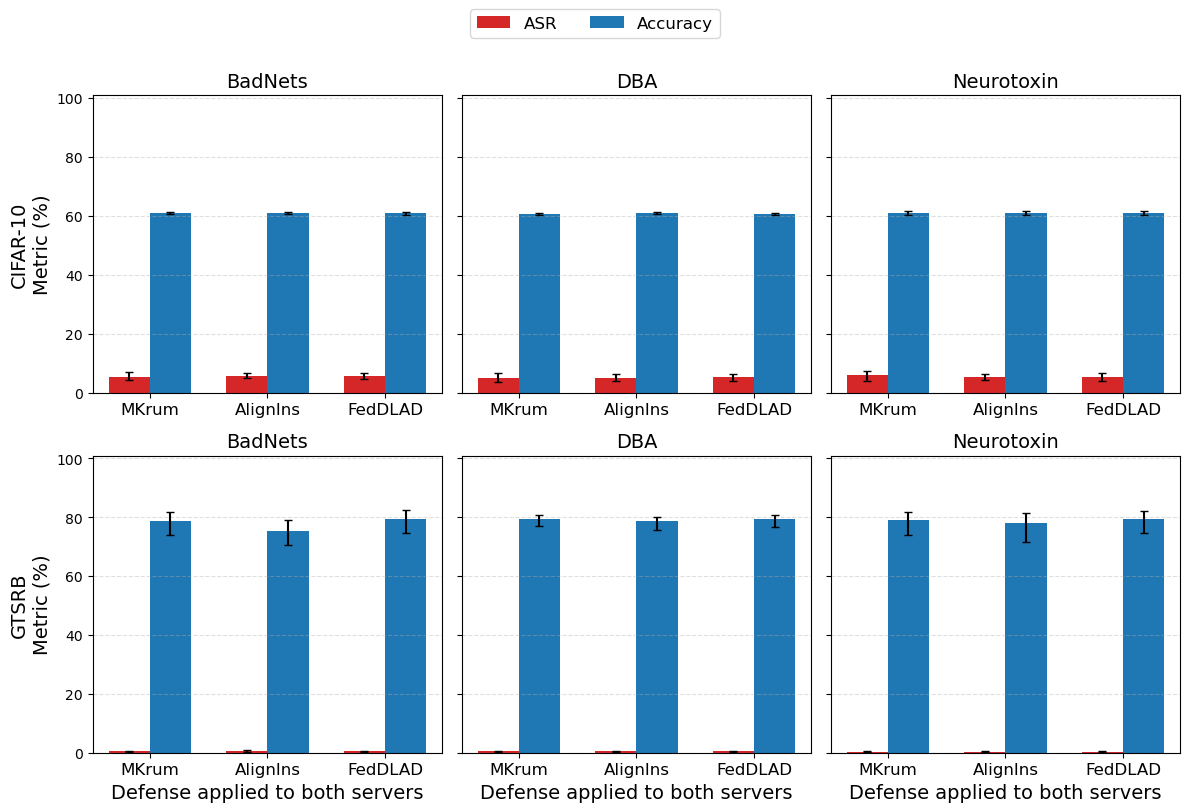

In [15]:
fig = combined_figure(agg, 50, "CIFAR-10 & GTSRB — defense_start_round=50 (defence applied to both servers)")
plt.show()


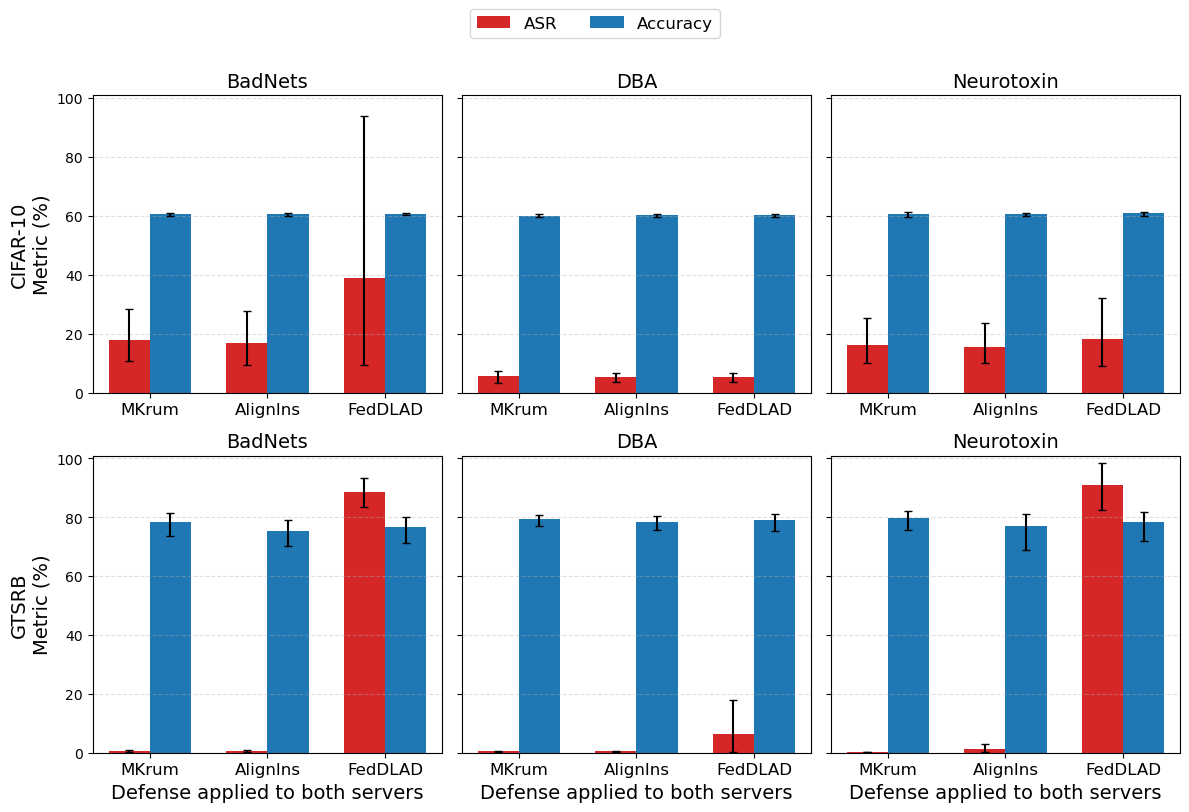

In [16]:
fig = combined_figure(agg, 100, "CIFAR-10 & GTSRB — defense_start_round=100")
plt.show()


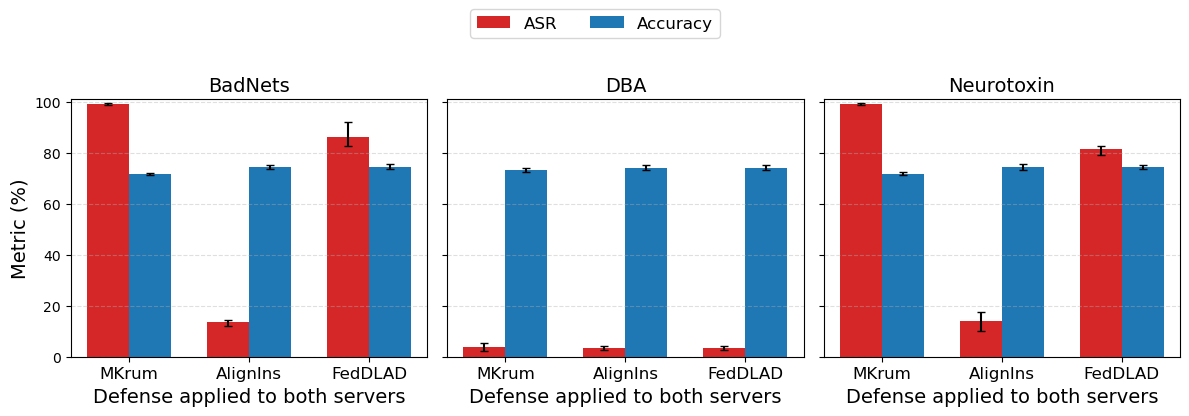

In [17]:
fig = single_dataset_figure(agg, "cifar10", 200, "CIFAR-10 — defense_start_round=200")
plt.show()


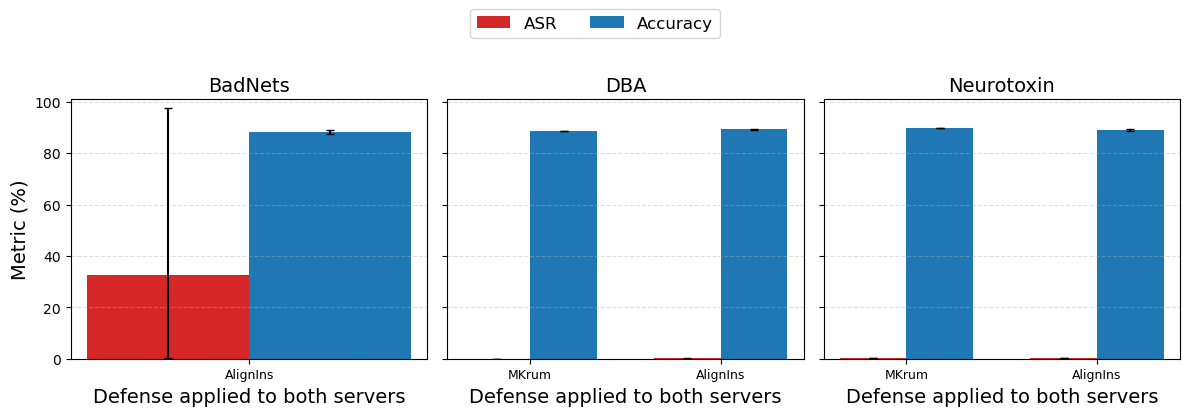

In [10]:
fig = single_dataset_figure(agg, "gtsrb", 200, "GTSRB — defense_start_round=200")
plt.show()


MNIST defense_start_round values with diagonal data: [50, 100]


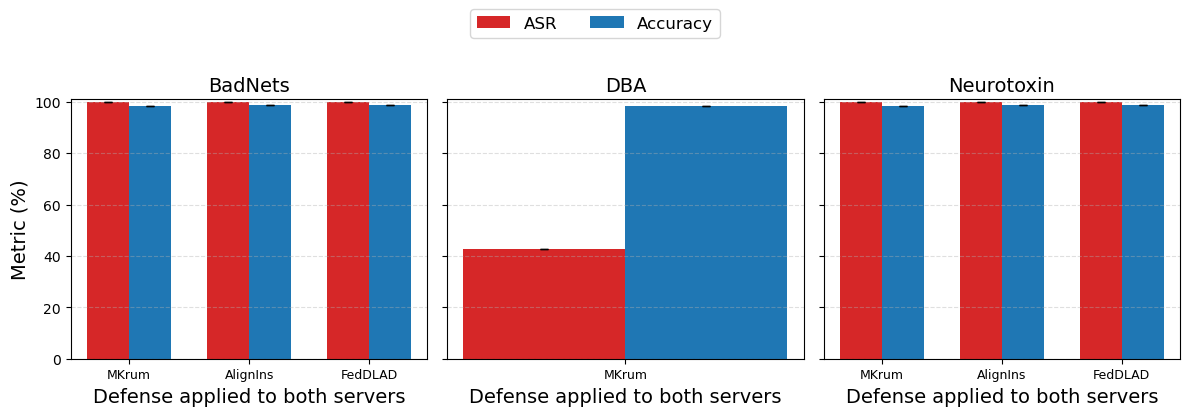

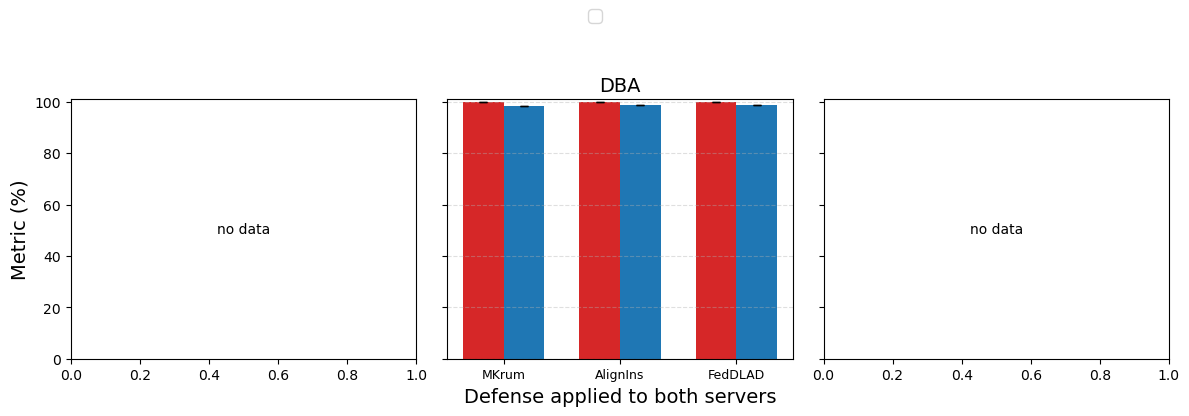

In [11]:
mnist_dsrs = sorted(agg.loc[agg["data"] == "mnist", "defense_start_round"].unique())
print("MNIST defense_start_round values with diagonal data:", mnist_dsrs)
for dsr in mnist_dsrs:
    fig = single_dataset_figure(agg, "mnist", dsr, f"MNIST — defense_start_round={dsr} (single seed, no seed 43/44 sweep yet)")
    plt.show()


## 5. Round-vs-ASR line plot (mean line + min/max band)

Same defense (AlignIns, applied on both servers) tracked across training,
for each of the defense-start-round experiments -- the seed-averaged version
of `plotting.ipynb`'s last figure, ASR only. Needs full per-round history
(not just the final-round summary used above), so it's fetched separately.


In [12]:
def fetch_history_for(data, aggr, defense_start_round_values=None):
    rows = []
    for project in PROJECTS:
        for r in api.runs(project, per_page=200):
            cfg = r.config
            dsr = cfg.get("defense_start_round", 1)
            run_data = cfg.get("data")
            attack = cfg.get("attack")
            if isinstance(attack, list) or isinstance(run_data, list):
                continue
            if run_data != data or dsr is None or dsr == 1:
                continue
            if defense_start_round_values is not None and dsr not in defense_start_round_values:
                continue
            run_aggr = OVERRIDE_AS_DIAG.get(r.id, cfg.get("aggr", "avg"))
            aggr_server_raw = cfg.get("aggr_server", "avg")
            eff = run_aggr if aggr_server_raw == "same" else aggr_server_raw
            if run_aggr != aggr or eff != aggr:
                continue
            if r.state != "finished":
                continue
            rounds_cfg = cfg.get("rounds", 200)
            if (dict(r.summary).get("round") or 0) < rounds_cfg:
                continue
            seed = cfg.get("seed", 0)
            if data != "gtsrb" and seed == 0 and project != "adavarts-tuwien/sfl-with-start-round":
                continue  # untrusted seed0 (see section 2)
            h = r.history(keys=["round", "asr"], pandas=True)
            if h.empty:
                continue
            h["attack"] = attack
            h["dsr"] = dsr
            h["seed"] = seed
            rows.append(h)
    if not rows:
        return pd.DataFrame(columns=["round", "asr", "attack", "dsr", "seed"])
    return pd.concat(rows, ignore_index=True).dropna(subset=["round"])


hist = fetch_history_for("cifar10", "alignins")
print(f"{len(hist)} history rows fetched")

agg_hist = hist.groupby(["attack", "dsr", "round"]).agg(
    asr_mean=("asr", "mean"), asr_min=("asr", "min"), asr_max=("asr", "max"),
    n=("seed", "nunique"),
).reset_index()
print(agg_hist.groupby(["attack", "dsr"])["n"].max())


8100 history rows fetched
attack      dsr
DBA         50     3
            100    3
            200    3
badnet      50     3
            100    3
            200    3
neurotoxin  50     3
            100    3
            200    3
Name: n, dtype: int64


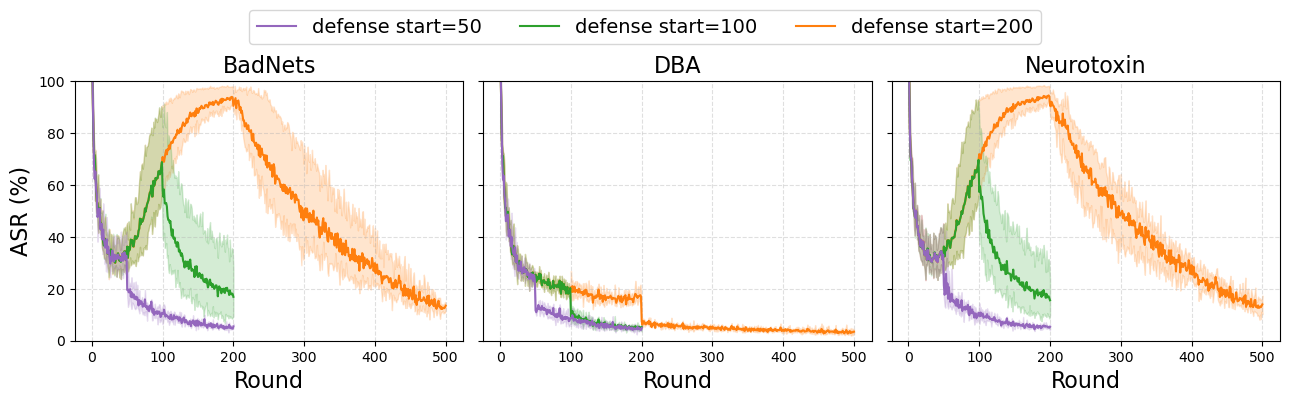

In [13]:
# Drawn in this order (200 first, then 100, then 50) so the shorter/later
# start-round curves layer on top -- also determines the legend order.
DSR_PLOT_ORDER = [200, 100, 50, 300]
DSR_COLORS = {200: "#ff7f0e", 100: "#2ca02c", 50: "#9467bd", 300: "#8c564b"}

fig, axes = plt.subplots(1, len(ATTACKS), figsize=(13, 4), sharex=True, sharey=True)
for i, attack in enumerate(ATTACKS):
    sub = agg_hist[agg_hist["attack"] == attack]
    present = [d for d in DSR_PLOT_ORDER if d in sub["dsr"].unique()]
    for dsr in present:
        s = sub[sub["dsr"] == dsr].sort_values("round")
        color = DSR_COLORS.get(dsr, "gray")
        axes[i].plot(s["round"], s["asr_mean"] * 100, color=color, label=f"defense start={dsr}")
        axes[i].fill_between(s["round"], s["asr_min"] * 100, s["asr_max"] * 100, color=color, alpha=0.2)
    axes[i].set_xlabel("Round", fontsize=16)
    axes[i].set_title(ATTACK_LABEL.get(attack, attack), fontsize=16)
axes[0].set_ylabel("ASR (%)", fontsize=16)
for ax in axes.flat:
    ax.set_ylim(0, 100)
    ax.grid(True, linestyle="--", alpha=0.4)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles[::-1], labels[::-1], loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, 1.02), fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()
